<a href="https://colab.research.google.com/github/junseo25/ds2002-walmart-hurricane-project/blob/main/notebooks/scratch/Copy_of_2026_10_30_%E2%80%94_Midterm_Progress_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the updated professor data, aligned with Helene.
url = (
    "https://raw.githubusercontent.com/jasontpv/DS2002FA26/"
    "main/notebooks/06-midterm-walmart/data/walmart_transactions.csv"
)
transactions = pd.read_csv(url)

# Remove exact duplicates before changing values.
clean = transactions.drop_duplicates().copy()

# Measure positive units sold; exclude returns and missing quantities.
clean['quantity'] = pd.to_numeric(clean['quantity'], errors='coerce')
clean = clean.loc[
    clean['quantity'].notna() & (clean['quantity'] > 0)
].copy()

# Parse timestamps and preserve missing dates for reporting.
clean['date'] = pd.to_datetime(
    clean['timestamp'],
    format='mixed',
    errors='coerce'
).dt.normalize()

# Only dated records can contribute to daily analysis.
dated_sales = clean.dropna(subset=['date']).copy()
LANDFALL = pd.Timestamp('2024-09-26')

print('Original rows:', len(transactions))
print('After deduplication and quantity filtering:', len(clean))
print('Undated rows excluded from daily analysis:',
      clean['date'].isna().sum())
print('Rows available for daily analysis:', len(dated_sales))
print('Date range:',
      dated_sales['date'].min(), 'to', dated_sales['date'].max())

Original rows: 25562
After deduplication and quantity filtering: 25402
Undated rows excluded from daily analysis: 881
Rows available for daily analysis: 24521
Date range: 2024-09-01 00:00:00 to 2024-09-30 00:00:00


### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [2]:
# TODO: the numbers
# Total positive units sold each day.
daily_units = (
    dated_sales.groupby('date')['quantity']
    .sum()
    .sort_index()
)

# Explicit windows: normal period and three days before landfall.
baseline_start = '2024-09-01'
baseline_end = '2024-09-15'
surge_start = '2024-09-23'
surge_end = '2024-09-25'

baseline = daily_units.reindex(
    pd.date_range(baseline_start, baseline_end)
)
surge = daily_units.reindex(
    pd.date_range(surge_start, surge_end)
)

# Confirm every requested day has data.
assert baseline.notna().all(), 'Missing baseline days'
assert surge.notna().all(), 'Missing surge days'

baseline_average = baseline.mean()
surge_average = surge.mean()

assert baseline_average > 0, 'Baseline must be positive'
surge_multiple = surge_average / baseline_average

print(f'Baseline: {baseline_start} through {baseline_end}')
print(f'Baseline average: {baseline_average:,.2f} units/day')
print(f'Surge: {surge_start} through {surge_end}')
print(f'Surge average: {surge_average:,.2f} units/day')
print(f'Surge multiple: {surge_multiple:.2f}×')

Baseline: 2024-09-01 through 2024-09-15
Baseline average: 1,103.00 units/day
Surge: 2024-09-23 through 2024-09-25
Surge average: 3,519.00 units/day
Surge multiple: 3.19×


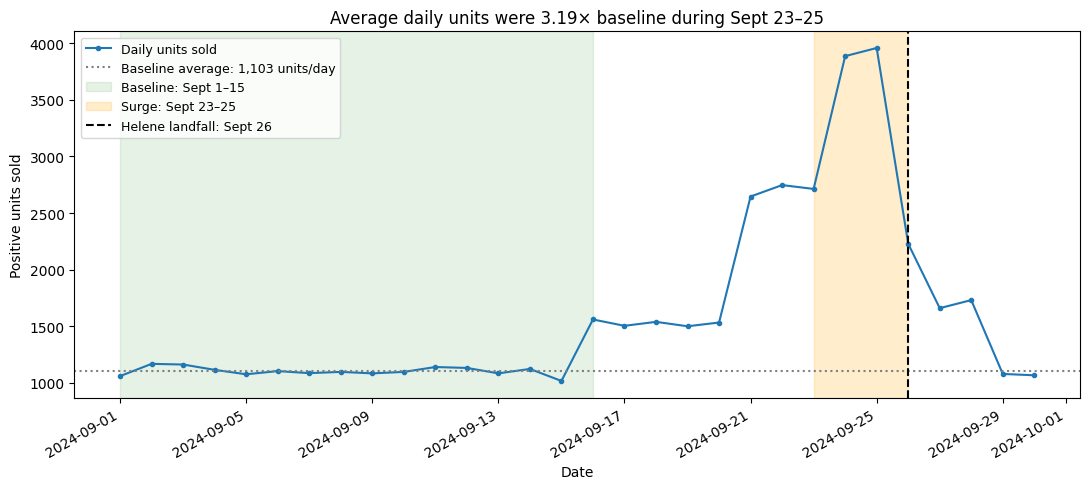

Coverage: exact duplicates removed; only positive quantities included; 881 undated rows excluded from daily analysis.


In [3]:
# TODO: the chart
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    daily_units.index,
    daily_units.values,
    marker='o',
    markersize=3,
    label='Daily units sold'
)

ax.axhline(
    baseline_average,
    color='gray',
    linestyle=':',
    label=f'Baseline average: {baseline_average:,.0f} units/day'
)

ax.axvspan(
    pd.Timestamp(baseline_start),
    pd.Timestamp(baseline_end) + pd.Timedelta(days=1),
    color='green', alpha=0.10,
    label='Baseline: Sept 1–15'
)

ax.axvspan(
    pd.Timestamp(surge_start),
    pd.Timestamp(surge_end) + pd.Timedelta(days=1),
    color='orange', alpha=0.20,
    label='Surge: Sept 23–25'
)

ax.axvline(
    LANDFALL,
    color='black',
    linestyle='--',
    label='Helene landfall: Sept 26'
)

ax.set_title(
    f'Average daily units were {surge_multiple:.2f}× baseline '
    'during Sept 23–25'
)
ax.set_xlabel('Date')
ax.set_ylabel('Positive units sold')
ax.legend(fontsize=9)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print(
    'Coverage: exact duplicates removed; only positive quantities '
    'included; 881 undated rows excluded from daily analysis.'
)

**Q1 answer, in one sentence a manager could read:** _..._

Average daily positive units increased from 1,103 during September 1-15 to 3,519 during September 23-25, a 3.19x multiple

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [4]:
# TODO
# Product-family mapping based on the catalog names.
families = {
    'POPTART-STRAW': ['PT-12', 'SKU#459812', 'POPTART-STRAW', 'PT_STRAWBERRY'],
    'WATER24PK': ['WTR-24', 'WATER24PK', 'WTR_24PK'],
    'BATT_AA_4PK': ['BATT-100', 'BAT-AA4', 'BATT_AA_4PK'],
    'LED-FLASH': ['FLASH-01', 'LED-FLASH'],
    'LTBEER24': ['BEER-24', 'LTBEER24'],
    'GAME-MONO': ['BG-MONO', 'MONOPOLY-01', 'GAME-MONO'],
    'PLAYCARD': ['CARDS-01', 'PLAYCARD-STD'],
    'ROKUSTREAM': ['STREAM-01', 'ROKU-STD'],
    'SOUP-CAN': ['SOUP-CAN', 'CNSOUP-01'],
    'WHITEBREAD': ['BREAD-WH', 'WHITEBREAD'],
    'PEANUTBTR': ['PB-16', 'PNUTBTR-16'],
    'CANDLE-EMRG': ['CNDL-EM', 'CANDLE-EMRG'],
    'FIRSTAID-KIT': ['FAID-01', 'FIRSTAID-KIT'],
    'PORTCHARGER': ['CHRG-PORT', 'PORTCHARGER'],
    'CHIPVARIETY': ['CHIPS-VP', 'CHIPVARIETY'],
    'PAPERTOWEL': ['PTOWEL-6', 'PAPERTOWEL6'],
    'TOILETPAPER12': ['TP-12', 'TOILETPAPER12'],
    'DIAPERS-S3': ['DIAP-S3', 'DIAPERS-3'],
    'BABYFORMULA': ['BFORM-01', 'BABYFORMULA'],
    'TARP-HD': ['TARP-HD', 'HDTARP-01'],
}

# Turn the family lists into a raw-SKU-to-canonical-SKU dictionary.
sku_map = {
    raw_sku: canonical
    for canonical, variants in families.items()
    for raw_sku in variants
}

# Use the same dated, positive-quantity sales as our charts.
consolidated_sales = dated_sales.copy()
consolidated_sales['canonical_sku'] = (
    consolidated_sales['sku']
    .map(sku_map)
    .fillna(consolidated_sales['sku'])
)

# Consolidation must preserve rows and quantities.
assert len(consolidated_sales) == len(dated_sales)
assert consolidated_sales['canonical_sku'].notna().all()
assert (
    consolidated_sales['quantity'].sum()
    == dated_sales['quantity'].sum()
)

# Rank families with more than one raw SKU in the sales data.
family_summary = (
    consolidated_sales.groupby('canonical_sku')
    .agg(
        total_units=('quantity', 'sum'),
        raw_sku_count=('sku', 'nunique')
    )
    .query('raw_sku_count > 1')
    .sort_values('total_units', ascending=False)
)

display(family_summary)

print('Distinct raw SKUs in dated sales:',
      dated_sales['sku'].nunique())

print('Canonical products:',
      consolidated_sales['canonical_sku'].nunique())

print('Units before consolidation:',
      dated_sales['quantity'].sum())

print('Units after consolidation:',
      consolidated_sales['quantity'].sum())

print('\nLargest consolidated family:')
display(family_summary.head(1))

,total_units,raw_sku_count
canonical_sku,,
WATER24PK,5037,3
POPTART-STRAW,5005,4
BATT_AA_4PK,4154,3
LED-FLASH,2814,2
CANDLE-EMRG,2546,2
SOUP-CAN,2538,2
LTBEER24,2493,2
PLAYCARD,2312,2
WHITEBREAD,2239,2


Distinct raw SKUs in dated sales: 45
Canonical products: 20
Units before consolidation: 47897
Units after consolidation: 47897

Largest consolidated family:


,total_units,raw_sku_count
canonical_sku,,
WATER24PK,5037,3


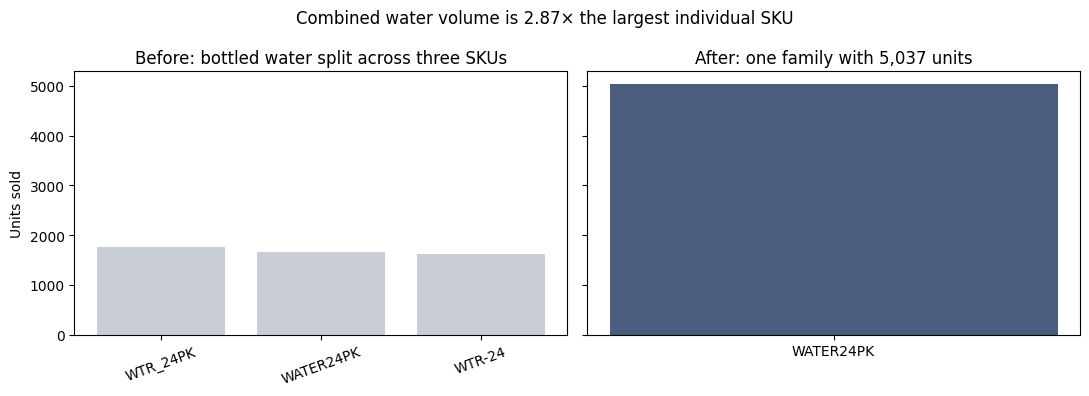

Raw SKU totals:
sku
WTR_24PK     1758
WATER24PK    1657
WTR-24       1622
Name: quantity, dtype: int64
Combined total: 5,037 units
Multiple versus largest raw SKU: 2.87×
Unit-preservation assertion passed.


In [5]:
largest_family = family_summary.index[0]

family_sales = consolidated_sales.loc[
    consolidated_sales['canonical_sku'] == largest_family
]

fragmented = (
    family_sales.groupby('sku')['quantity']
    .sum()
    .sort_values(ascending=False)
)

consolidated_total = fragmented.sum()
consolidation_multiple = consolidated_total / fragmented.max()

# Prove that consolidation preserved units across all products.
assert (
    consolidated_sales['quantity'].sum()
    == dated_sales['quantity'].sum()
), 'Consolidation changed unit totals'

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('Before: bottled water split across three SKUs')
axes[0].set_ylabel('Units sold')
axes[0].tick_params(axis='x', labelrotation=20)

axes[1].bar(
    [largest_family], [consolidated_total], color='#4a5d7e'
)
axes[1].set_title(
    f'After: one family with {consolidated_total:,.0f} units'
)

fig.suptitle(
    f'Combined water volume is {consolidation_multiple:.2f}× '
    'the largest individual SKU'
)
plt.tight_layout()
plt.show()

print('Raw SKU totals:')
print(fragmented)
print(f'Combined total: {consolidated_total:,.0f} units')
print(f'Multiple versus largest raw SKU: {consolidation_multiple:.2f}×')
print('Unit-preservation assertion passed.')

**Q2 answer:** _..._

Water sales were fragmented across three main identifiers while consolidation exposes their combined volume without adding sales information.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [6]:
# TODO

import requests
import time

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.5383, lon=-81.3792, tries=3):
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start,
        'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=15)

        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue

        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue

        # Other HTTP errors fail immediately.
        r.raise_for_status()

        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

weather = daily_weather('2024-09-01', '2024-09-30')
weather_pulled_at = pd.Timestamp.now(tz='America/New_York')

print('Location: Orlando, 28.5383, -81.3792')
print('Endpoint:', BASE)
print('Timezone: America/New_York')
print('Retrieved:', weather_pulled_at.isoformat())
print('Weather rows:', len(weather))
print('Source:', weather['source'].unique())

display(weather.head())

Location: Orlando, 28.5383, -81.3792
Endpoint: https://archive-api.open-meteo.com/v1/archive
Timezone: America/New_York
Retrieved: 2026-11-01T23:02:16.939955-05:00
Weather rows: 30
Source: ['open-meteo']


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,6.4,18.7,open-meteo
1,2024-09-02,22.0,12.7,open-meteo
2,2024-09-03,32.7,20.6,open-meteo
3,2024-09-04,21.2,12.6,open-meteo
4,2024-09-05,20.8,15.2,open-meteo


In [7]:
# Standardize the store IDs before selecting Orlando.
q3_sales = dated_sales.copy()

q3_sales['store_id'] = (
    q3_sales['store_id'].astype('string')
    .str.upper()
    .str.strip()
    .str.replace(r'[^A-Z0-9]', '', regex=True)
    .str.replace(r'^FL(\d{3})$', r'FL-\1', regex=True)
)

# FL-239 is Orlando in the store file.
orlando_sales = q3_sales.loc[
    q3_sales['store_id'] == 'FL-239'
].copy()

assert not orlando_sales.empty, 'No Orlando sales found'

# One row per day, measuring positive units sold.
orlando_daily = (
    orlando_sales.groupby('date')
    .agg(
        units=('quantity', 'sum'),
        sales_records=('quantity', 'size')
    )
    .reset_index()
    .sort_values('date')
)

# Keep every sales day and require unique dates on both sides.
weather_joined = orlando_daily.merge(
    weather,
    on='date',
    how='left',
    validate='one_to_one',
    indicator=True
)

# Verify that the join preserved sales.
assert len(weather_joined) == len(orlando_daily)
assert weather_joined['units'].sum() == orlando_daily['units'].sum()
assert weather_joined['_merge'].eq('both').all(), \
    'Some sales days have no matching weather date'

print('Sales days before join:', len(orlando_daily))
print('Rows after join:', len(weather_joined))
print('Units before join:', orlando_daily['units'].sum())
print('Units after join:', weather_joined['units'].sum())
print('Match counts:')
print(weather_joined['_merge'].value_counts())
print('Missing weather measurements:')
print(
    weather_joined[
        ['precipitation_sum', 'windspeed_10m_max']
    ].isna().sum()
)

display(weather_joined.head())

Sales days before join: 30
Rows after join: 30
Units before join: 3911
Units after join: 3911
Match counts:
_merge
both          30
left_only      0
right_only     0
Name: count, dtype: int64
Missing weather measurements:
precipitation_sum    0
windspeed_10m_max    0
dtype: int64


,date,units,sales_records,precipitation_sum,windspeed_10m_max,source,_merge
0,2024-09-01,82,42,6.4,18.7,open-meteo,both
1,2024-09-02,84,45,22.0,12.7,open-meteo,both
2,2024-09-03,101,48,32.7,20.6,open-meteo,both
3,2024-09-04,92,47,21.2,12.6,open-meteo,both
4,2024-09-05,109,60,20.8,15.2,open-meteo,both


In [8]:
# Sort chronologically before shifting weather values.
weather_joined = weather_joined.sort_values('date').reset_index(drop=True)

# Confirm that shifting one row really means shifting one day.
assert weather_joined['date'].diff().dropna().eq(
    pd.Timedelta(days=1)
).all(), 'Dates are not consecutive'

# Same-day relationships.
same_day_rain = weather_joined['units'].corr(
    weather_joined['precipitation_sum']
)
same_day_wind = weather_joined['units'].corr(
    weather_joined['windspeed_10m_max']
)

print(f'Same-day units vs rainfall: r = {same_day_rain:.3f}')
print(f'Same-day units vs wind: r = {same_day_wind:.3f}')
print('Same-day paired observations:', len(weather_joined))

# Compare today's sales with wind 0–4 days later.
results = []

for k in range(5):
    pairs = pd.DataFrame({
        'units_today': weather_joined['units'],
        'wind_later': weather_joined['windspeed_10m_max'].shift(-k)
    }).dropna()

    results.append({
        'wind_days_later': k,
        'paired_days': len(pairs),
        'correlation': pairs['units_today'].corr(pairs['wind_later'])
    })

lag_results = pd.DataFrame(results)
display(lag_results.round(3))

Same-day units vs rainfall: r = -0.255
Same-day units vs wind: r = 0.458
Same-day paired observations: 30


,wind_days_later,paired_days,correlation
0,0,30,0.458
1,1,29,0.688
2,2,28,0.773
3,3,27,0.669
4,4,26,0.545


In [9]:
print(lag_results.round(3).to_string(index=False))

 wind_days_later  paired_days  correlation
               0           30        0.458
               1           29        0.688
               2           28        0.773
               3           27        0.669
               4           26        0.545


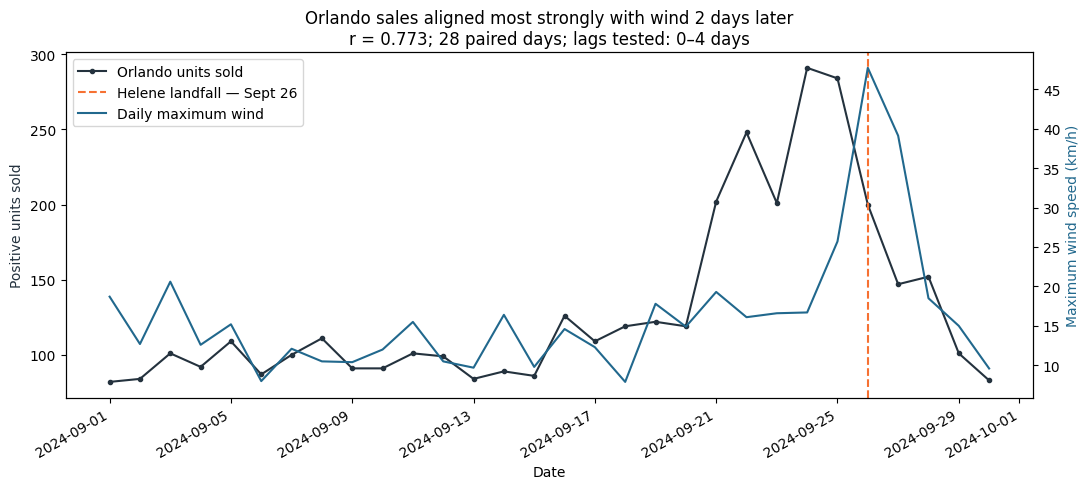

Source: Open-Meteo API; no fallback used.
Join: 30 sales days retained; 3,911 units preserved.


In [10]:
best_lag = lag_results.loc[lag_results['correlation'].idxmax()]
lag_days = int(best_lag['wind_days_later'])
paired_days = int(best_lag['paired_days'])
lag_r = best_lag['correlation']

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    weather_joined['date'],
    weather_joined['units'],
    color='#24323E',
    marker='o',
    markersize=3,
    label='Orlando units sold'
)
ax.set_xlabel('Date')
ax.set_ylabel('Positive units sold', color='#24323E')

ax2 = ax.twinx()
ax2.plot(
    weather_joined['date'],
    weather_joined['windspeed_10m_max'],
    color='#21688D',
    label='Daily maximum wind'
)
ax2.set_ylabel('Maximum wind speed (km/h)', color='#21688D')

ax.axvline(
    LANDFALL,
    color='#F67132',
    linestyle='--',
    label='Helene landfall — Sept 26'
)

ax.set_title(
    f'Orlando sales aligned most strongly with wind {lag_days} days later\n'
    f'r = {lag_r:.3f}; {paired_days} paired days; lags tested: 0–4 days'
)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left')

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print('Source: Open-Meteo API; no fallback used.')
print('Join: 30 sales days retained; 3,911 units preserved.')

**Q3 answer, with its caveat:** _..._

*   The same-day wind correlation was 0.458 across 30 days
*   Pairing sales with wind two days later increased it to 0.773 across 28 days, consistent with purchasing ahead of stronger winds.
*   This is an explanotry association for one store during one month. Comparing several lags and selecting the strongest doesn't prove causation.
*   Sales timestamps were interpreted as local time. However, that assumption will still need confirmation.



### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** _..._

Lakeland had the highest surge multiple (3.45×) and Orlando the lowest (2.76×).

**Q5 (signal or artifact):** _..._

Not started

### Self-check

In [12]:
progress = {
    'q1_multiple': float(surge_multiple),            # TODO: a number
    'q1_baseline_window': 'September 1-15, 2024',   # TODO: stated explicitly
    'q2_canonical_products': int(consolidated_sales['canonical_sku'].nunique()),  # TODO: a number
    'q3_join_rows_preserved': (
        len(weather_joined) == len(orlando_daily)
        and weather_joined['units'].sum()
        == orlando_daily['units'].sum()), # TODO: True/False
    'q3_days_in_correlation': paired_days, # TODO: a number
    'charts_with_message_titles': 3,  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 3.1903898458748867
PASS - q1_baseline_window = September 1-15, 2024
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 28
PASS - charts_with_message_titles = 3
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

_your answer here_